# Enterprise Agentic RAG Engine - master execution notebook

Runs the complete project end to end by executing the nine milestone notebooks in order (environment -> parsing -> indexing -> hybrid retrieval -> reranker -> generation -> guardrail -> API -> evaluation) and then presents the final scorecard. Each milestone notebook is saved with its outputs.

Heavy steps are cached: reranker fine-tuning (`scripts/train_reranker.py`) and the evaluation runs are re-used if their artifacts exist. Delete `models/bge-reranker-large-finetuned/` or `artifacts/eval/` to force a full re-run.

In [1]:
import os, sys, json, time, warnings, pathlib
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
from rag import config

In [2]:
import nbformat
from nbclient import NotebookClient
STEPS = ["01_environment_diagnostics", "02_document_parsing", "03_vector_indexing", "04_hybrid_retrieval",
         "05_reranker_integration", "06_rag_synthesis", "07_guardrail_verifier", "08_api_ui_server", "09_evaluation_scorecard"]
timings = []
for name in STEPS:
    path = ROOT / "notebooks" / f"{name}.ipynb"
    nb = nbformat.read(path, as_version=4)
    t = time.time()
    NotebookClient(nb, timeout=None, kernel_name="python3", resources={"metadata": {"path": str(path.parent)}}).execute()
    nbformat.write(nb, path)
    timings.append({"milestone": name, "seconds": round(time.time() - t, 1), "status": "ok"})
    print(f"{name:32s} done in {timings[-1]['seconds']:7.1f}s")
pd.DataFrame(timings)

[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


01_environment_diagnostics       done in     6.0s


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


02_document_parsing              done in     1.6s


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


...

[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


08_api_ui_server                 done in     9.6s


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


09_evaluation_scorecard          done in     4.9s


,milestone,seconds,status
0,01_environment_diagnostics,6.0,ok
1,02_document_parsing,1.6,ok
2,03_vector_indexing,12.1,ok
3,04_hybrid_retrieval,18.0,ok
4,05_reranker_integration,233.3,ok
5,06_rag_synthesis,19.8,ok
6,07_guardrail_verifier,51.3,ok
7,08_api_ui_server,9.6,ok
8,09_evaluation_scorecard,4.9,ok


## Final results

In [3]:
comp = json.loads((config.ARTIFACT_DIR / "reranker_comparison.json").read_text())
print("Reranker fine-tuning (200 held-out queries):")
display(pd.DataFrame({k: comp[k] for k in ("hybrid_rrf_no_rerank", "pretrained_reranker", "finetuned_reranker")}).T.round(4))
print("Guardrail stress test:", json.loads((config.ARTIFACT_DIR / "guardrail_stress.json").read_text()))
pd.read_json(config.ARTIFACT_DIR / "scorecard.json")

Reranker fine-tuning (200 held-out queries):


,context_precision,context_recall,mrr,hit@1,answer_chunk@1
hybrid_rrf_no_rerank,0.8584,0.995,0.8658,0.760,0.765
pretrained_reranker,0.9744,1.000,0.9862,0.975,0.975
finetuned_reranker,0.9722,0.995,0.9950,0.995,0.995


Guardrail stress test: {'n': 120, 'correct_accepted': 1.0, 'corrupted_caught': 1.0, 'foreign_caught': 1.0}


,metric,target,naive,pipeline (base),final system (LoRA),target met (final)
0,"Context precision (RAGAS def., gold-page labels)",>= 0.90,0.793,0.991,0.991,1.0
1,"Context precision (RAGAS, LLM judge)",>= 0.90,0.832,0.990,0.990,1.0
2,"Context recall (RAGAS, LLM judge)",-,0.995,1.000,1.000,NaN
3,"Faithfulness (RAGAS, judge sees generator input)",>= 0.95,0.971,0.997,0.997,1.0
4,"Faithfulness (RAGAS, page-text-only judge view)",(info),0.854,0.891,NaN,NaN
5,Answer relevancy (RAGAS),-,0.933,0.950,0.871,NaN
6,Citation accuracy (gold page cited),>= 0.95,0.968,0.995,1.000,1.0
7,End-to-end latency p95 (s),< 3.5,1.160,2.320,1.979,1.0
8,Answer correctness (semantic match),-,0.920,0.980,0.995,NaN
9,Answer correctness (strict exact match),-,0.905,0.955,0.980,NaN


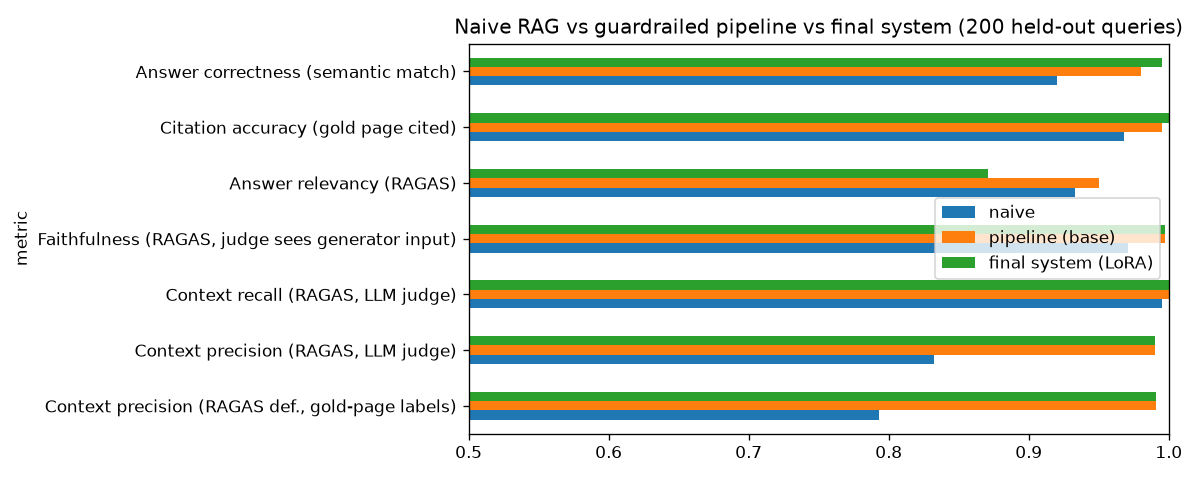

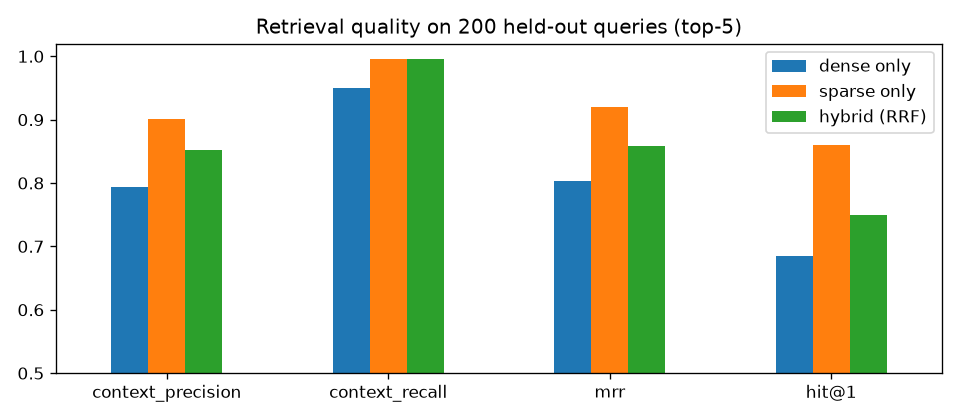

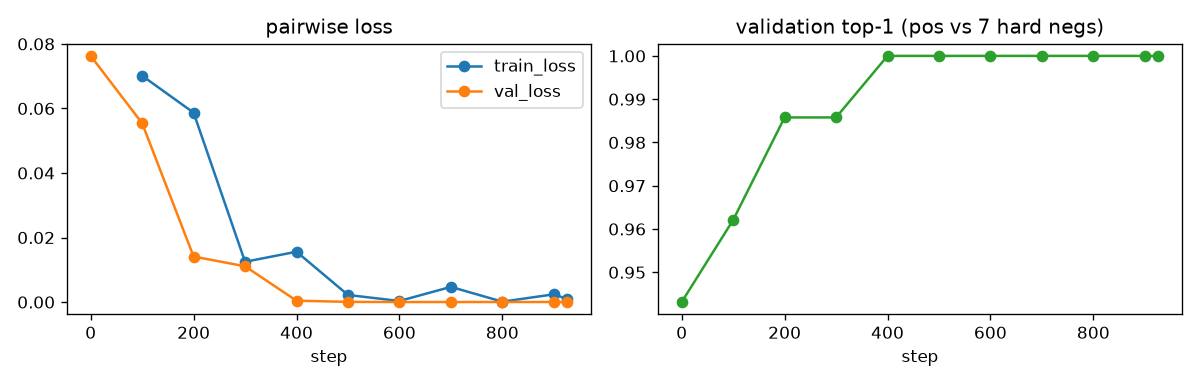

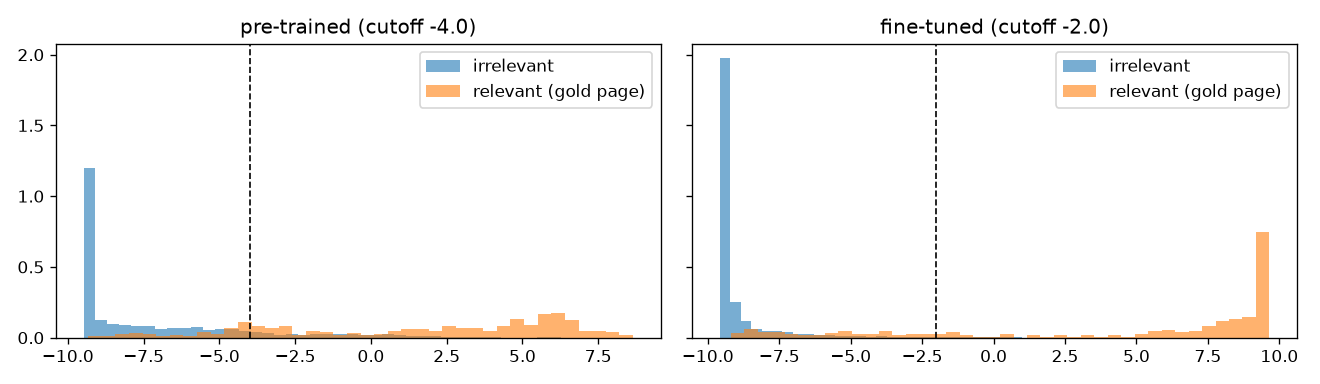

In [4]:
from IPython.display import Image, display
for f in ("scorecard.png", "retrieval_comparison.png", "reranker_training_curve.png", "reranker_score_separation.png"):
    p = config.ARTIFACT_DIR / f
    if p.exists(): display(Image(str(p), width=760))